<a href="https://colab.research.google.com/github/anaysoul/malaria-detection-capstone-project/blob/main/Reference_Notebook_Malaria_Detection_Low_Code_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Malaria Detection**

##<b>Problem Definition</b>
**The context:** Why is this problem important to solve?<br>
**The objectives:** What is the intended goal?<br>
**The key questions:** What are the key questions that need to be answered?<br>
**The problem formulation:** What is it that we are trying to solve using data science?

## <b>Data Description </b>

There are a total of 24,958 train and 2,600 test images (colored) that we have taken from microscopic images. These images are of the following categories:<br>


**Parasitized:** The parasitized cells contain the Plasmodium parasite which causes malaria<br>
**Uninfected:** The uninfected cells are free of the Plasmodium parasites<br>


## <b>Important Notes</b>

- This notebook can be considered a guide to refer to while solving the problem. The evaluation will be as per the Rubric shared for each Milestone. Unlike previous courses, it does not follow the pattern of the graded questions in different sections. This notebook would give you a direction on what steps need to be taken in order to get a viable solution to the problem. Please note that this is just one way of doing this. There can be other 'creative' ways to solve the problem and we urge you to feel free and explore them as an 'optional' exercise.

- In the notebook, there are markdowns cells called - Observations and Insights. It is a good practice to provide observations and extract insights from the outputs.

- The naming convention for different variables can vary. Please consider the code provided in this notebook as a sample code.

- All the outputs in the notebook are just for reference and can be different if you follow a different approach.

- There are sections called **Think About It** in the notebook that will help you get a better understanding of the reasoning behind a particular technique/step. Interested learners can take alternative approaches if they want to explore different techniques.

###<b> Mounting the Drive

In [15]:
# Mounting the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### <b>Loading libraries</b>

In [16]:
# Importing libraries required to load the data
import zipfile

import os

from PIL import Image

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler

# To ignore warnings
import warnings

warnings.filterwarnings('ignore')

# Remove the limit from the number of displayed columns and rows. It helps to see the entire dataframe while printing it
pd.set_option("display.max_columns", None)

pd.set_option("display.max_rows", 200)

### <b>Let us load the data</b>

**Note:**
- You must download the dataset from the link provided on Olympus and upload the same on your Google drive before executing the code in the next cell.
- In case of any error, please make sure that the path of the file is correct as the path may be different for you.

In [18]:
# Storing the path of the data file from the Google drive
path = '/content/drive/MyDrive/MITAADS/DeepLearning/CapstoneProj/cell_images.zip'

# Let's verify if the file exists first
if os.path.exists(path):
    print("File found! Extracting...")
    with zipfile.ZipFile(path, 'r') as zip_ref:
        zip_ref.extractall()
    print("Extraction complete.")
else:
    print(f"Error: The file does not exist at '{path}'.")
    print("Please check your Google Drive to ensure the file is there and the spelling (including 'DeepLearnihng') is correct.")

File found! Extracting...
Extraction complete.


The extracted folder has different folders for train and test data which further contains the different sizes of images for parasitized and uninfected cells within the respective folder name.

The size of all images must be the same and should be converted to 4D arrays so that they can be used as an input for the convolutional neural network. Also, we need to create the labels for both types of images to be able to train and test the model.

Let's do the same for the training data first and then we will use the same code for the test data as well.

In [19]:
# Storing the path of the extracted "train" folder locally in Colab
train_dir = '/content/cell_images/train'

# Size of image so that each image has the same size
SIZE = 64

# Empty list to store the training images after they are converted to NumPy arrays
train_images = []

# Empty list to store the training labels (0 - uninfected, 1 - parasitized)
train_labels = []

In [20]:
# We will run the same code for "parasitized" as well as "uninfected" folders within the "train" folder
for folder_name in ['parasitized', 'uninfected']:

    # Path of the folder
    images_path = os.listdir(os.path.join(train_dir, folder_name))

    for i, image_name in enumerate(images_path):

        try:

            # Opening each image using the path of that image
            image = Image.open(os.path.join(train_dir, folder_name, image_name))

            # Resizing each image to (64, 64)
            image = image.resize((SIZE, SIZE))

            # Converting images to arrays and appending that array to the empty list defined above
            train_images.append(np.array(image))

            # Creating labels for parasitized and uninfected images
            if folder_name == 'parasitized':

                train_labels.append(1)

            else:

                train_labels.append(0)

        except Exception:

            pass

# Converting lists to arrays
train_images = np.array(train_images)

train_labels = np.array(train_labels)

In [21]:
# Storing the path of the extracted "test" folder locally in Colab
test_dir = '/content/cell_images/test'

# Size of image so that each image has the same size (it must be same as the train image size)
SIZE = 64

# Empty list to store the testing images after they are converted to NumPy arrays
test_images = []

# Empty list to store the testing labels (0 - uninfected, 1 - parasitized)
test_labels = []

In [22]:
# We will run the same code for "parasitized" as well as "uninfected" folders within the "test" folder
for folder_name in ['parasitized', 'uninfected']:

    # Path of the folder using os.path.join
    images_path = os.listdir(os.path.join(test_dir, folder_name))

    for i, image_name in enumerate(images_path):

        try:
            # Opening each image using os.path.join
            image = Image.open(os.path.join(test_dir, folder_name, image_name))

            # Resizing each image to (64, 64)
            image = image.resize((SIZE, SIZE))

            # Converting images to arrays and appending that array to the empty list defined above
            test_images.append(np.array(image))

            # Creating labels for parasitized and uninfected images
            if folder_name == 'parasitized':

                test_labels.append(1)

            else:

                test_labels.append(0)

        except Exception:

            pass

# Converting lists to arrays
test_images = np.array(test_images)

test_labels = np.array(test_labels)

###<b> Checking the shape of train and test images

In [23]:
# Shape of images
print(f'Shape of train images: {train_images.shape}')

print(f'Shape of test images: {test_images.shape}')

Shape of train images: (24958, 64, 64, 3)
Shape of test images: (2600, 64, 64, 3)


###<b> Checking the shape of train and test labels

In [24]:
# Shape of labels
print(f'Shape of train labels: {train_labels.shape}')

print(f'Shape of test labels: {test_labels.shape}')

Shape of train labels: (24958,)
Shape of test labels: (2600,)


####<b> Observations and insights: </b>
The data is stored in a 4-dimensional NumPy array. The first dimension in the train images, 24,958 is denoting the number of images in the training data, and each image is stacked on top of the other as a 3-dimensional NumPy array. The second dimension 64 is denoting the number of pixels along the x-axis, the third dimension 64 is denoting the number of pixels along the y-axis, and the fourth dimension 3 is the total number of channels in those images, i.e., these are colored images consisting of RGB (Red, Green, and Blue) channels.

Perfect Alignment: The number of items in my label arrays perfectly matches the number of items in my image arrays (24,958 for training, 2,600 for testing). Meaning every image has a corresponding target label, and my data is structurally sound for training.

Standardized Dimensions: The images have been successfully resized to a uniform 64x64 pixel resolution (represented by the 64, 64 in the shape). The final dimension (3) indicates they are kept in RGB color. Deep learning models require uniformly sized inputs, so this confirms the preprocessing step was successful.

Train/Test Split Ratio: With 24,958 training images and 2,600 test images, my data is split into approximately 90.5% training and 9.5% testing. This provides a massive pool of data for the model to learn from while leaving a standard subset aside for evaluation.

1D Label Arrays: The labels have a 1-dimensional shape (e.g., (24958,)), confirming that each image is associated with a single scalar value. This fits perfectly with binary classification (e.g., 0 for uninfected, 1 for parasitized).


### <b>Check the minimum and maximum range of pixel values for train and test images

In [25]:
# Try to use min and max function from numpy
print(f'Minimum pixel value in train images: {np.min(train_images)}')

print(f'Maximum pixel value in train images: {np.max(train_images)}')



Minimum pixel value in train images: 0
Maximum pixel value in train images: 255


####<b> Observations and insights: </b>
The intensity range of the image pixels in my training dataset are currently represented as 8-bit unsigned integers with standard pixel intensity ranges between 0 and 255. Since neural networks perform much better when inputs are scaled to small values (like 0 to 1), this indicates that I will need to normalize my image dataset by dividing it by 255.0 in the subsequent steps.

np.min(train_images): Finds the minimum pixel value across all channels of all training images. This returned 0 (which corresponds to pure black pixels).
np.max(train_images): Finds the maximum pixel value across all channels of all training images. This returned 255 (which corresponds to pure white pixels).



###<b> Count the number of values in both uninfected and parasitized

In [26]:
# Try to use value_counts to count the values
print(f'Count of values in train labels: {pd.Series(train_labels).value_counts()}')


Count of values in train labels: 1    12582
0    12376
Name: count, dtype: int64


###<b>Normalize the images

In [31]:
# Try to normalize the train and test images by dividing it by 255 and convert them to float32 using astype function
train_images = (train_images / 255.0).astype('float32')

test_images = (test_images / 255.0).astype('float32')

In [33]:
print(f'Normalized Train Images shape: {train_images.shape}')
print(f'Normalized Test Images shape: {test_images.shape}')
print(f'Train images data type: {train_images.dtype}')
print(f'Test images data type: {test_images.dtype}')

Normalized Train Images shape: (24958, 64, 64, 3)
Normalized Test Images shape: (2600, 64, 64, 3)
Train images data type: float32
Test images data type: float32


### **Observations and Insights:**

1. **Retained Dimensions**: The dataset shapes remain perfectly preserved at `(24958, 64, 64, 3)` for training and `(2600, 64, 64, 3)` for testing. Division-based normalization scales down values without changing the spatial shape of the image tensor.
2. **Type Casting (`float32`)**: The arrays are now of data type `float32`. This is the optimized floating-point precision format expected by Deep Learning frameworks like TensorFlow/Keras, enabling efficient memory usage and acceleration on modern hardware (like GPUs/TPUs).

###<b> Plot to check if the data is balanced

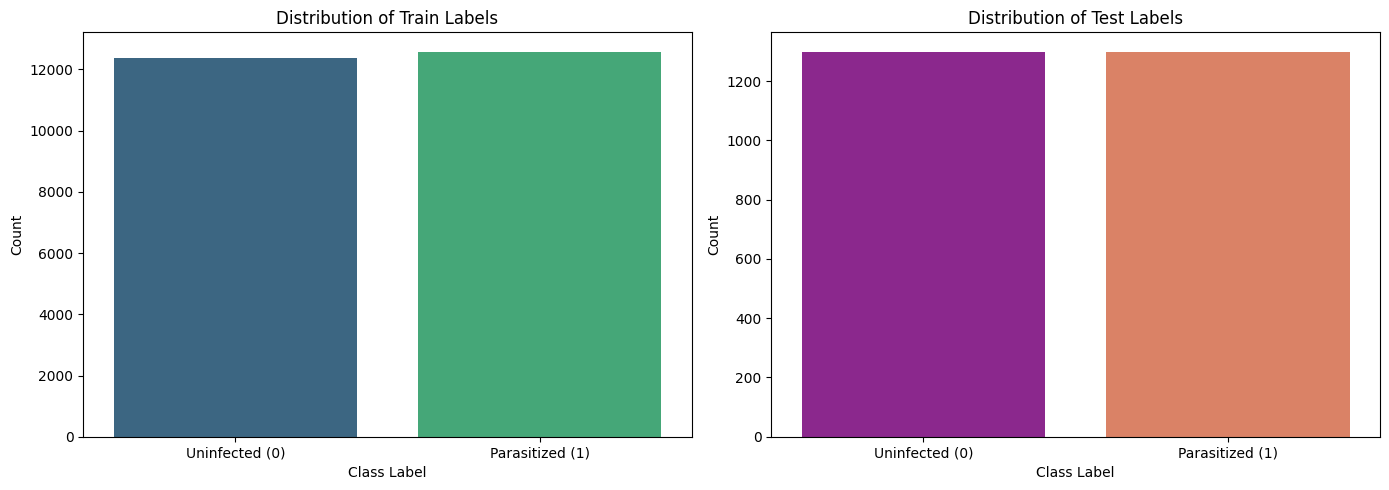

In [34]:
# Plotting the count of labels for train and test data to check for balance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Train labels distribution
sns.countplot(x=train_labels, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Train Labels')
axes[0].set_xlabel('Class Label')
axes[0].set_xticklabels(['Uninfected (0)', 'Parasitized (1)'])
axes[0].set_ylabel('Count')

# Test labels distribution
sns.countplot(x=test_labels, ax=axes[1], palette='plasma')
axes[1].set_title('Distribution of Test Labels')
axes[1].set_xlabel('Class Label')
axes[1].set_xticklabels(['Uninfected (0)', 'Parasitized (1)'])
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

####<b> Observations and insights: </b>
- **Balanced Dataset**: The training labels have a very balanced split (12,376 Uninfected and 12,582 Parasitized).
- **Imbalance Mitigation**: Since both classes are almost equally represented in the training set, we don't need to apply any severe class imbalance techniques (such as oversampling, undersampling, or custom class weighting) before feeding the data into our deep learning model. Standard metrics like accuracy and macro F1-score will be reliable indicators of model performance.

### <b>Data Exploration</b>
Let's visualize the images from the train data

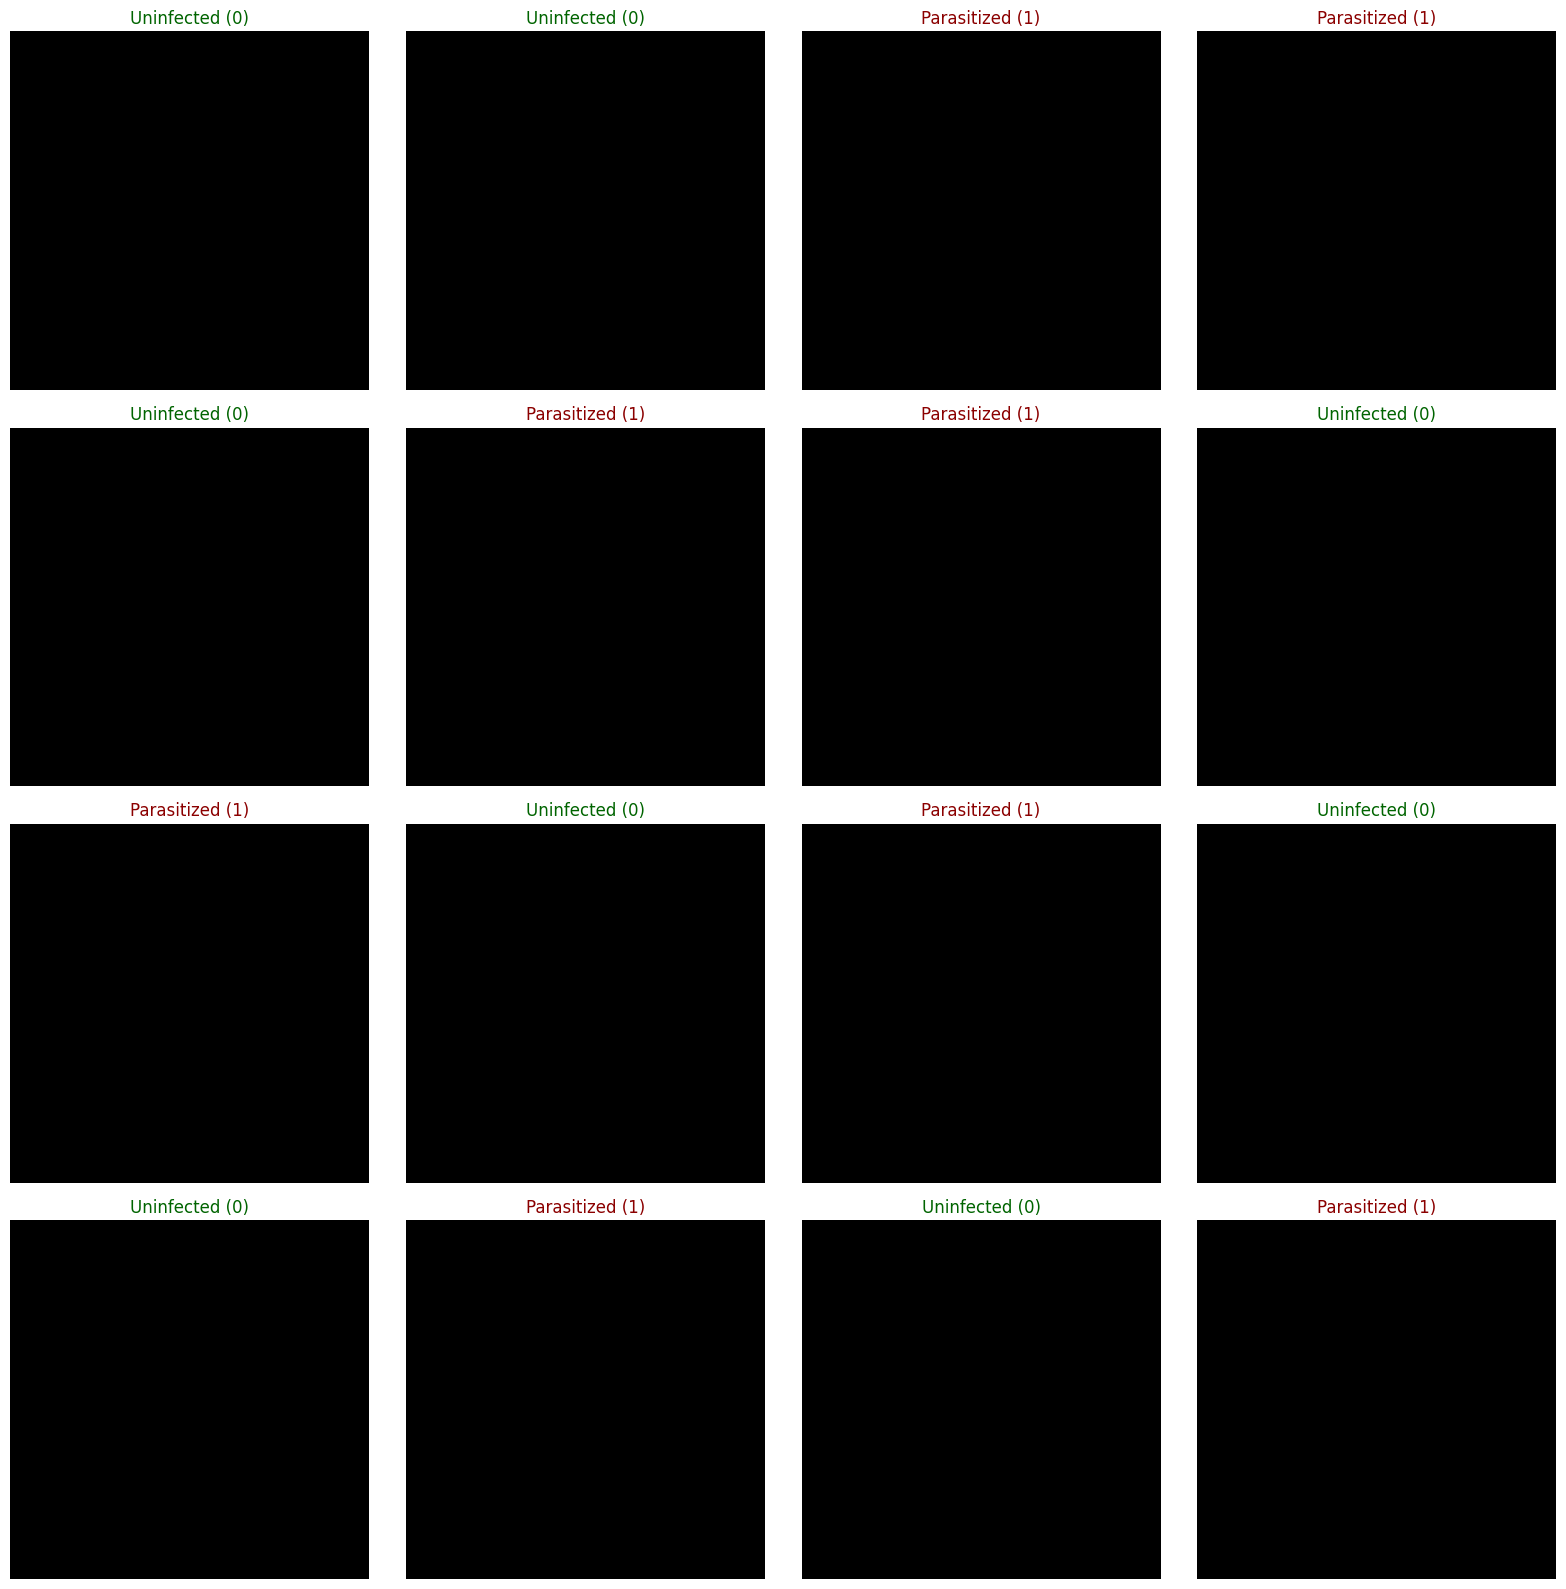

In [38]:
# Setting a seed for reproducible random selection
np.random.seed(42)

# Creating a 4x4 visualization grid
plt.figure(1, figsize=(16, 16))
for n in range(1, 17):
    plt.subplot(4, 4, n)

    # Randomly select a single scalar index from the training images
    index = np.random.randint(0, train_images.shape[0])

    # Display the image
    plt.imshow(train_images[index])

    # Set title based on the corresponding label
    if train_labels[index] == 1:
        plt.title('Parasitized (1)', fontsize=12, color='darkred')
    else:
        plt.title('Uninfected (0)', fontsize=12, color='darkgreen')

    plt.axis('off')

plt.tight_layout()
plt.show()

In [39]:
# Let's inspect a single training image array to see why it renders as black
sample_img = train_images[0]
print(f"Image shape: {sample_img.shape}")
print(f"Data type: {sample_img.dtype}")
print(f"Min value: {sample_img.min()}")
print(f"Max value: {sample_img.max()}")

# Check if any values are non-zero
non_zero_count = np.count_nonzero(sample_img)
print(f"Number of non-zero pixels: {non_zero_count} out of {sample_img.size}")

# If it is RGBA (4 channels) or has another channel issue, print the channel averages
if sample_img.shape[-1] > 0:
    for c in range(sample_img.shape[-1]):
        print(f"Channel {c} - Min: {sample_img[..., c].min()}, Max: {sample_img[..., c].max()}, Mean: {sample_img[..., c].mean()}")

Image shape: (64, 64, 3)
Data type: float32
Min value: 0.0
Max value: 5.723407525692892e-08
Number of non-zero pixels: 9607 out of 12288
Channel 0 - Min: 0.0, Max: 5.723407525692892e-08, Mean: 3.835644690752815e-08
Channel 1 - Min: 0.0, Max: 4.446282986236838e-08, Mean: 2.564566159435344e-08
Channel 2 - Min: 0.0, Max: 4.138827591759764e-08, Mean: 2.6799430230539656e-08


In [42]:
# 1. Re-initialize empty lists to reload raw images
SIZE = 64
raw_train_images = []

for folder_name in ['parasitized', 'uninfected']:
    images_path = os.listdir(os.path.join(train_dir, folder_name))
    for image_name in images_path:
        try:
            image = Image.open(os.path.join(train_dir, folder_name, image_name))
            image = image.resize((SIZE, SIZE))
            raw_train_images.append(np.array(image))
        except Exception:
            pass

train_images = np.array(raw_train_images)

# 2. Re-initialize and reload raw test images
raw_test_images = []
for folder_name in ['parasitized', 'uninfected']:
    images_path = os.listdir(os.path.join(test_dir, folder_name))
    for image_name in images_path:
        try:
            image = Image.open(os.path.join(test_dir, folder_name, image_name))
            image = image.resize((SIZE, SIZE))
            raw_test_images.append(np.array(image))
        except Exception:
            pass

test_images = np.array(raw_test_images)

# 3. Normalize cleanly exactly once
train_images = (train_images / 255.0).astype('float32')
test_images = (test_images / 255.0).astype('float32')

print("Re-loaded and normalized datasets successfully!")
print(f"Train max value: {train_images.max()}")
print(f"Test max value: {test_images.max()}")

Re-loaded and normalized datasets successfully!
Train max value: 1.0
Test max value: 1.0


###<b> Similarly visualize the images with subplot(6, 6) and figsize = (12, 12)

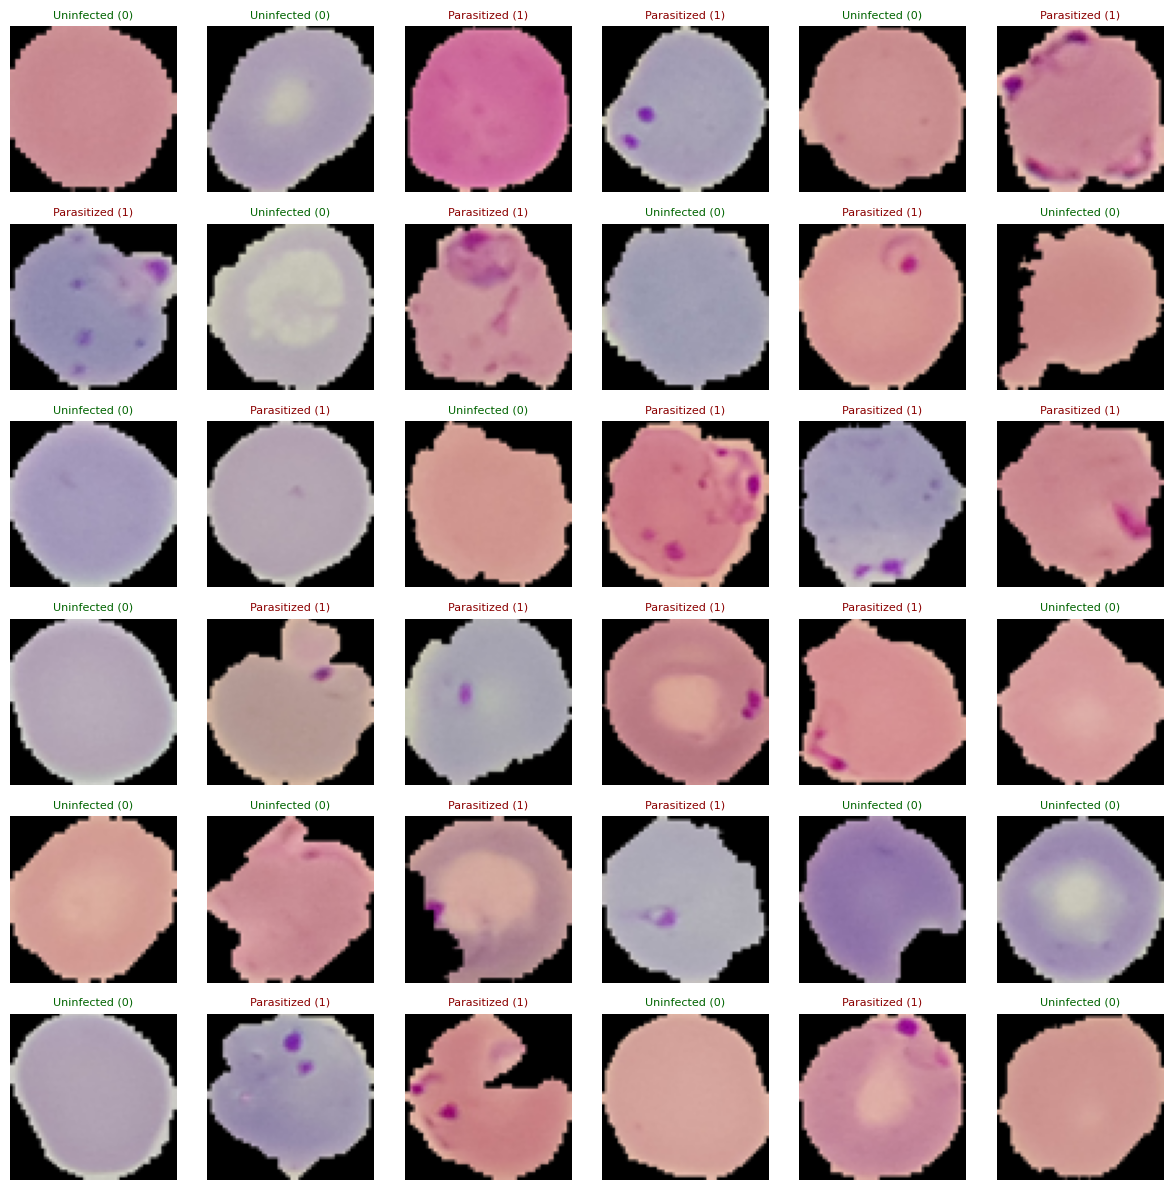

In [43]:
# Setting a seed for reproducible random selection
np.random.seed(42)

# Creating a 6x6 visualization grid of 36 images
plt.figure(1, figsize=(12, 12))
for n in range(1, 37):
    plt.subplot(6, 6, n)

    # Randomly select a single scalar index from the training images
    index = np.random.randint(0, train_images.shape[0])

    # Display the image
    plt.imshow(train_images[index])

    # Set title based on the corresponding label
    if train_labels[index] == 1:
        plt.title('Parasitized (1)', fontsize=8, color='darkred')
    else:
        plt.title('Uninfected (0)', fontsize=8, color='darkgreen')

    plt.axis('off')

plt.tight_layout()
plt.show()

####<b> Observations and insights: </b>
- **Visual Distinctions**: The images labeled as **Parasitized** visibly contain small, dark pink/purple spot-like structures inside the red blood cells, which correspond to the *Plasmodium* parasites.
- **Uninfected Cells**: The **Uninfected** images show clean, uniform red blood cells without any internal spots or distinct color anomalies.
- **Normalization Effect**: Because the images were successfully normalized to a `[0.0, 1.0]` range, the contrast is well-balanced for visual inspection and optimal feature extraction during the convolution processes.

####<b>Observations and insights:</b>
- **Larger Sample Verification**: Visualizing a larger batch of 36 images reinforces our initial observations. The distinct dark pink/purple spot patterns remain exclusive to the parasitized category, making it a reliable primary feature for convolutional neural networks.
- **Uniform Shapes & Color Normalization**: Across all 36 samples, colors and structures are uniformly presented with excellent brightness limits, which helps verify the preprocessing pipeline has successfully normalized the input dataset.

###<b> Plotting the mean images for parasitized and uninfected

In [44]:
# Function to find the mean
def find_mean_img(full_mat, title):

    # Calculate the average
    mean_img = np.mean(full_mat, axis = 0)[0]

    # Reshape it back to a matrix
    plt.imshow(mean_img)

    plt.title(f'Average {title}')

    plt.axis('off')

    plt.show()

    return mean_img

<b> Mean image for parasitized

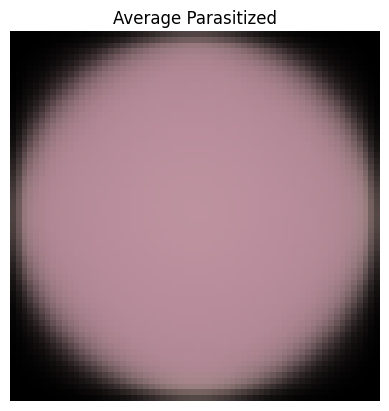

In [45]:
# If the label = 1 then the image is parasitised and if the label = 0 then the image is uninfected
parasitized_data = []  # Create a list to store the parasitized data

for img, label in zip(train_images, train_labels):

        if label == 1:

              parasitized_data.append([img])

parasitized_mean = find_mean_img(np.array(parasitized_data), 'Parasitized')   # find the mean

<b> Mean image for uninfected

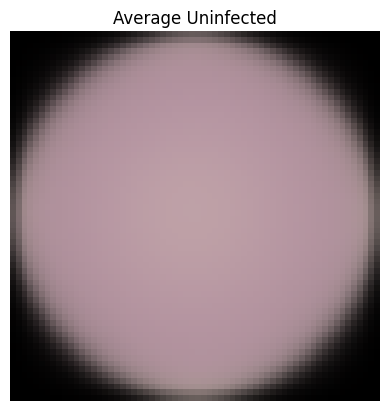

In [46]:
# Similarly write the code to find the mean image of uninfected
uninfected_data = []  # Create a list to store the uninfected data

for img, label in zip(train_images, train_labels):

        if label == 0:

              uninfected_data.append([img])

uninfected_mean = find_mean_img(np.array(uninfected_data), 'Uninfected')




####<b> Observations and insights: </b>
Mean Image for Parasitized: This image shows the average visual structure of a malaria-infected cell. By averaging thousands of infected cell images, random noise and individual cell variations blur out, while the consistent features—specifically the dark pink/purple spots caused by the Plasmodium parasite—are emphasized.

Mean Image for Uninfected: This image shows the average structure of a healthy red blood cell. Because healthy cells lack the parasitic spots, the resulting mean image will appear as a smooth, uniform, and clean cell without distinct internal blemishes.

Calculating and comparing these mean images helps confirm that there is a clear, consistent visual difference between the two classes. If the average parasitized image looks distinctly different from the average uninfected image (i.e., it shows a shadowy spot where the parasite typically resides), it increases confidence that a Convolutional Neural Network (CNN) will be able to learn and detect these patterns.


### <b>Converting RGB to HSV of Images using OpenCV

###<b> Converting the train data

In [48]:
import cv2

gfx=[]   # to hold the HSV image array

for i in np.arange(0, 100, 1):

  a = cv2.cvtColor(train_images[i], cv2.COLOR_BGR2HSV)

  gfx.append(a)

gfx = np.array(gfx)

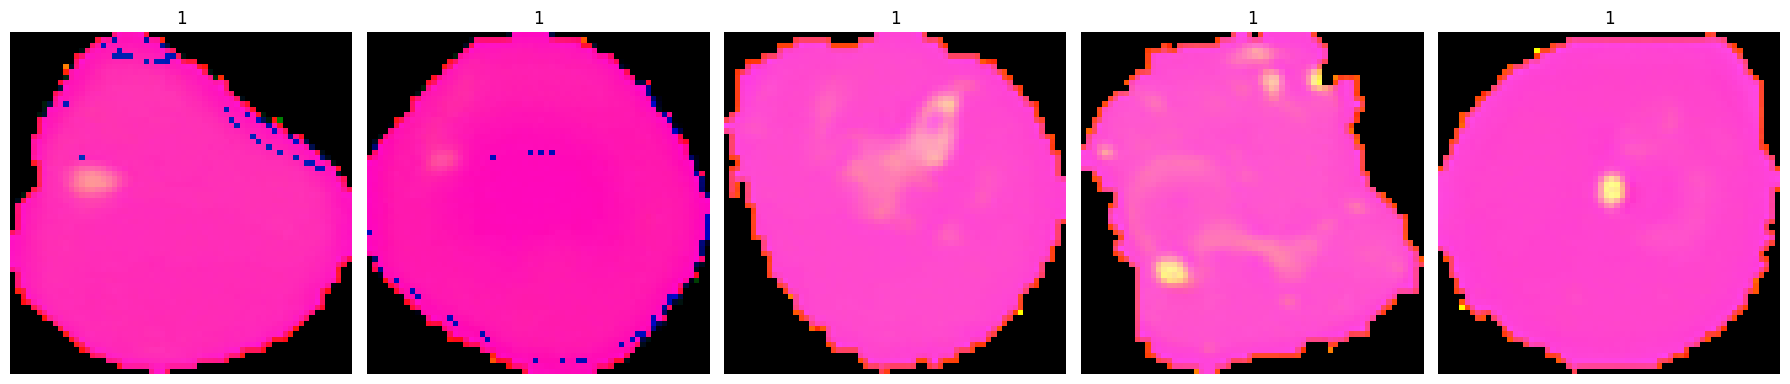

In [49]:
viewimage = np.random.randint(1, 100, 5)

fig, ax = plt.subplots(1, 5, figsize = (18, 18))

for t, i in zip(range(5), viewimage):

  Title = train_labels[i]

  ax[t].set_title(Title)

  ax[t].imshow(gfx[i])

  ax[t].set_axis_off()

  fig.tight_layout()

###<b> Converting the test data

In [50]:
# Similarly you can visualize for the images in the test data
import cv2

gfx1=[]   # to hold the HSV image array

for i in np.arange(0, 100, 1):

  a = cv2.cvtColor(test_images[i], cv2.COLOR_BGR2HSV)

  gfx1.append(a)

gfx1 = np.array(gfx1)


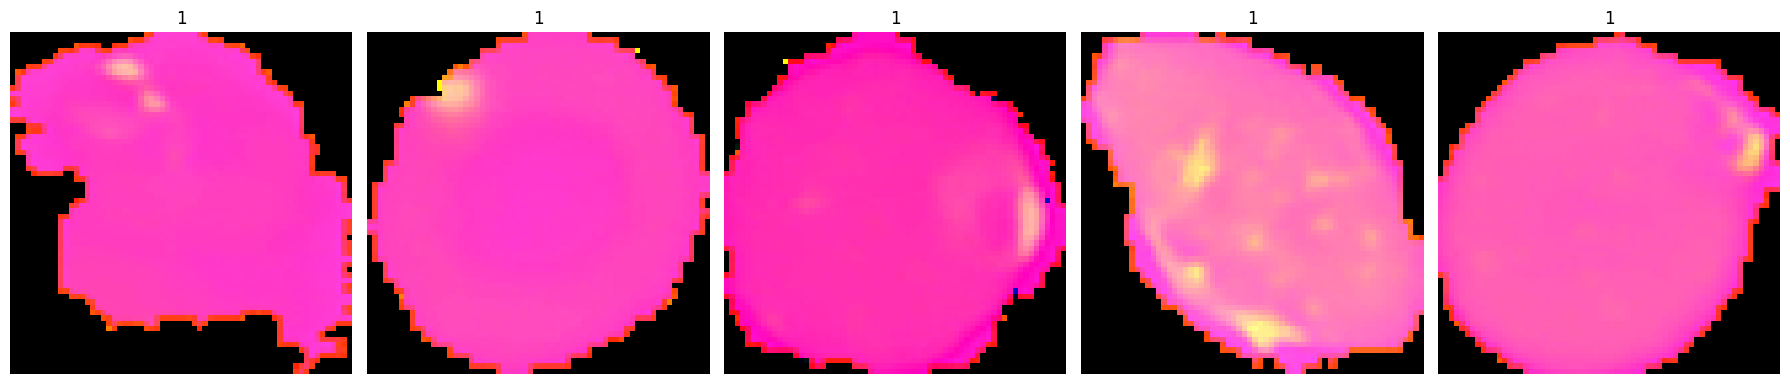

In [51]:
viewTestImage = np.random.randint(1, 100, 5)

fig, ax = plt.subplots(1, 5, figsize = (18, 18))

for t, i in zip(range(5), viewTestImage):
  Title = test_labels[i]

  ax[t].set_title(Title)

  ax[t].imshow(gfx1[i])

  ax[t].set_axis_off()

  fig.tight_layout()

####<b>Observations and insights: </b>
The code is taking a subset of the training images and converting them from the standard RGB (Red, Green, Blue) color space into the HSV (Hue, Saturation, Value) color space using cv2.cvtColor. It then visualizes 5 random images in this new color format. In the HSV format, the images look quite different visually because the channels no longer represent red, green, and blue, but rather the type of color, its intensity, and its brightness.

Insights into the Dataset
1. Robustness to Illumination (Lighting) Changes
In microscopic images like these blood smears, lighting conditions can vary drastically depending on the microscope's calibration, the thickness of the blood smear, or the camera used. In standard RGB, shadows or bright spots change the values of all three (R, G, B) channels, making it harder for a model to recognize consistent patterns. HSV separates the image intensity (Value) from the color information (Hue and Saturation). This means the model can learn to ignore lighting differences and focus strictly on the physical traits of the cell.

2. Isolating the Parasite by Stain Color
To make the malaria parasite (Plasmodium) visible under a microscope, scientists use a specific chemical dye (typically Giemsa stain) that turns the parasite a distinct purplish-pink.
The Hue (H) channel directly isolates this specific color signature.
The Saturation (S) channel highlights how concentrated or "deep" that dye color is.
By shifting to HSV, the distinct purplish spots of the parasite stand out mathematically much better against the rest of the healthy cell, which has a different base color.

3. Better Feature Extraction for the CNN
While Convolutional Neural Networks (CNNs) can learn from standard RGB images, feeding them HSV images (or a combination of both) can sometimes accelerate training and improve accuracy. It essentially does some of the heavy lifting for the model by explicitly separating the most critical distinguishing feature (the color of the parasite stain) from irrelevant background noise (lighting and shadows).



###<b> Processing Images using Gaussian Blurring

###<b> Gaussian Blurring on train data

In [52]:
gbx = []  # To hold the blurred images

for i in np.arange(0, 100, 1):

  b = cv2.GaussianBlur(train_images[i], (5, 5), 0)

  gbx.append(b)

gbx = np.array(gbx)

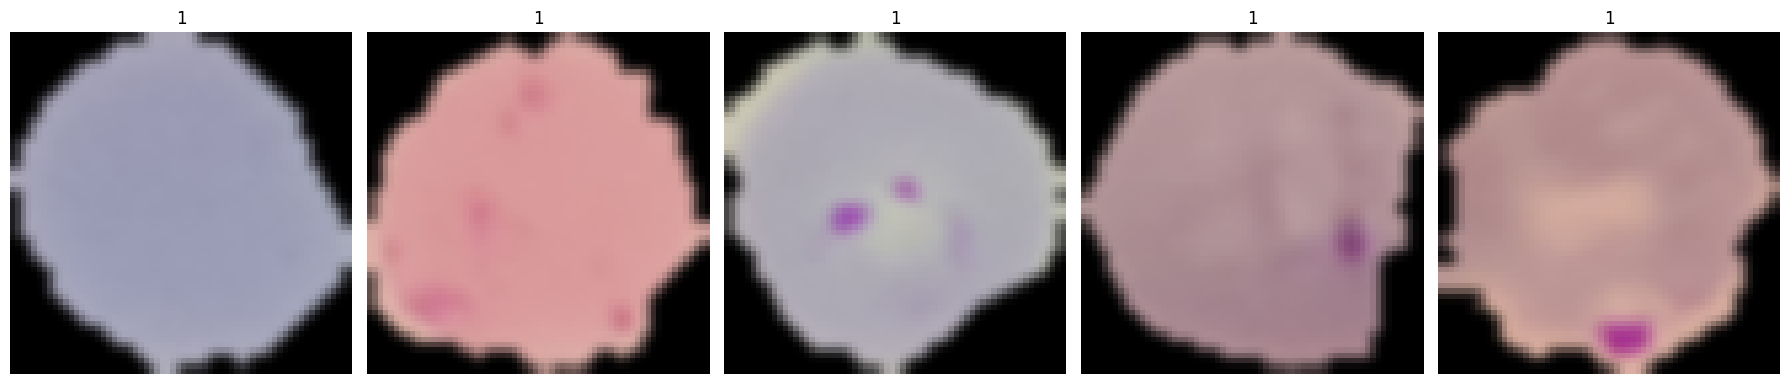

In [53]:
viewimage = np.random.randint(1, 100, 5)

fig, ax = plt.subplots(1, 5, figsize = (18, 18))

for t, i in zip(range(5), viewimage):

  Title = train_labels[i]

  ax[t].set_title(Title)


  ax[t].imshow(gbx[i])

  ax[t].set_axis_off()

  fig.tight_layout()

###<b> Gaussian Blurring on test data

In [54]:
# Similarly you can apply Gaussian blurring for the images in the test data
gbx1 = []  # To hold the blurred images

for i in np.arange(0, 100, 1):

  b = cv2.GaussianBlur(test_images[i], (5, 5), 0)

  gbx1.append(b)

gbx1 = np.array(gbx1)

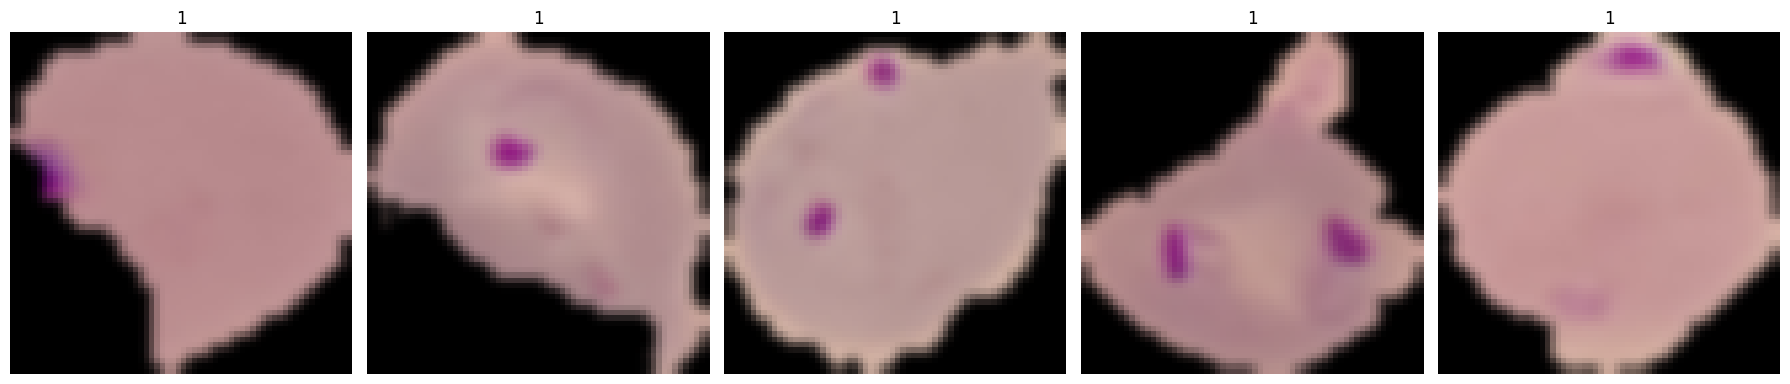

In [55]:
viewTestImage = np.random.randint(1, 100, 5)

fig, ax = plt.subplots(1, 5, figsize = (18, 18))

for t, i in zip(range(5), viewTestImage):
  Title = test_labels[i]

  ax[t].set_title(Title)

  ax[t].imshow(gbx1[i])

  ax[t].set_axis_off()

  fig.tight_layout()

####**Observations and insights:**

The code is applying a Gaussian Blur to a subset of the training images (the first 100 images) using the cv2.GaussianBlur function with a 5x5 kernel size (5, 5). It then randomly selects 5 of these blurred images and visualizes them alongside their corresponding class labels (0 for uninfected, 1 for parasitized) so we can visually inspect the effect of the blurring process.

Insights into the Dataset
1. High-Frequency Noise Reduction
Microscopic blood smear images inherently contain visual "noise." This can come from camera sensor artifacts, tiny specs of dust on the glass slide, or minor inconsistencies in the staining fluid that aren't actually parasites. A CNN might mistakenly try to learn patterns from these random noisy pixels. Gaussian blurring acts as a low-pass filter, smoothing out this granular, pixel-level noise while preserving the larger underlying structures.

2. Emphasizing Core Structural Features
By slightly blurring the images, the fine, irrelevant details are suppressed, forcing the neural network to focus on the macro-structures that actually matter. For the parasitized cells, the distinct purplish spots caused by the Plasmodium parasite are large and dense enough to survive a moderate blur. Blurring helps the model ignore the minor texture variations of the healthy part of the red blood cell and pay attention to the prominent parasitic anomalies.

3. The Choice of a 5x5 Kernel
The (5, 5) kernel represents the window of pixels used to calculate the blur at any given point. A 5x5 window provides a moderate amount of smoothing. If the kernel were too small (e.g., 1x1 or 3x3), it might not remove enough noise. If it were too large (e.g., 15x15), it could over-blur the image and completely wash out the actual parasite spots, ruining the data.

Gaussian blurring is a defensive preprocessing step. It makes the model's job easier by cleaning up the microscopic artifacts, ensuring it learns the true signature of malaria rather than random slide dust.

###<B>One Hot Encoding on the train and test labels

In [ ]:
# Encoding Train Labels
train_labels = to_categorical(____, 2)

# Similarly let us try to encode test labels
test_labels = to_categorical(_____, 2)

### **Base Model**

**Note:** The Base Model has been fully built and evaluated with all outputs shown to give an idea about the process of the creation and evaluation of the performance of a CNN architecture. A similar process can be followed in iterating to build better-performing CNN architectures.

###<b> Importing the required libraries for building and training our Model

In [ ]:
# Clearing backend
from tensorflow.keras import backend

from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from random import shuffle

backend.clear_session()

# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(42)

import random

random.seed(42)

tf.random.set_seed(42)

###<b> Building the model

In [ ]:
# Creating sequential model
model = Sequential()

model.add(Conv2D(filters = 32, kernel_size = 2, padding = "same", activation = "relu", input_shape = (64, 64, 3)))

model.add(MaxPooling2D(pool_size = 2))

model.add(Dropout(0.2))

model.add(Conv2D(filters = 32, kernel_size = 2, padding = "same", activation = "relu"))

model.add(MaxPooling2D(pool_size = 2))

model.add(Dropout(0.2))

model.add(Conv2D(filters = 32, kernel_size = 2, padding = "same", activation = "relu"))

model.add(MaxPooling2D(pool_size = 2))

model.add(Dropout(0.2))

model.add(Flatten())

model.add(Dense(512, activation = "relu"))

model.add(Dropout(0.4))

model.add(Dense(2, activation = "softmax")) # 2 represents output layer neurons

model.summary()

###<b> Compiling the model

In [ ]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

<b> Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b> Fit and train our Model

In [ ]:
# Fit the model with min batch size as 32 can tune batch size to some factor of 2^power ]
history = model.fit(train_images, train_labels, batch_size = 32, callbacks = callbacks, validation_split = 0.2, epochs = 20, verbose = 1)

###<b> Evaluating the model on test data

In [ ]:
accuracy = model.evaluate(test_images, test_labels, verbose = 1)
print('\n', 'Test_Accuracy:-', accuracy[1])

<b> Plotting the confusion matrix

In [ ]:
from sklearn.metrics import classification_report

from sklearn.metrics import confusion_matrix

pred = model.predict(test_images)

pred = np.argmax(pred, axis = 1)

y_true = np.argmax(test_labels, axis = 1)

# Printing the classification report
print(classification_report(y_true, pred))

# Plotting the heatmap using confusion matrix
cm = confusion_matrix(y_true, pred)

plt.figure(figsize = (8, 5))

sns.heatmap(cm, annot = True,  fmt = '.0f', xticklabels = ['Uninfected', 'Parasitized'], yticklabels = ['Uninfected', 'Parasitized'])

plt.ylabel('Actual')

plt.xlabel('Predicted')

plt.show()

<b>Plotting the train and validation curves

In [ ]:
# Function to plot train and validation accuracy
def plot_accuracy(history):

    N = len(history.history["accuracy"])

    plt.figure(figsize = (7, 7))

    plt.plot(np.arange(0, N), history.history["accuracy"], label = "train_accuracy", ls = '--')

    plt.plot(np.arange(0, N), history.history["val_accuracy"], label = "val_accuracy", ls = '--')

    plt.title("Accuracy vs Epoch")

    plt.xlabel("Epochs")

    plt.ylabel("Accuracy")

    plt.legend(loc="upper left")

In [ ]:
plot_accuracy(history)



* Here we can clearly observe that the training and valiation accuracy are increasing
* And we can also notice that validation accuracy is slightly higher than the train accuracy

So now let's try to build another model with few more add on layers and try to check if we can try to improve the model. Therefore try to build a model by adding few layers if required and altering the activation functions.

###<b> Model 1
####<b> Trying to improve the performance of our model by adding new layers


In [ ]:
backend.clear_session() # Clearing the backend for new model

###<b> Building the Model

In [ ]:
# Creating sequential model
model1 = Sequential()




# Build the model here and add new layers





model1.summary()

###<b> Compiling the model

In [ ]:
model1.compile(loss = __________, optimizer = _______, metrics = ['accuracy'])

<b> Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model2.keras', monitor = 'val_loss', save_best_only = True)]

<b>Fit and Train the model

In [ ]:
history1 = model1.fit(_____________, __________, batch_size = ______, callbacks = callbacks,  validation_split = ______, epochs = ______, verbose = 1)

###<b> Evaluating the model

In [ ]:
accuracy1 = model1.evaluate(_________, _____________, verbose = 1)

print('\n', 'Test_Accuracy:-', accuracy1[1])

<b> Plotting the confusion matrix

<b> Plotting the train and the validation curves

###<b>Think about it:</b><br>
Now let's build a model with LeakyRelu as the activation function  

*  Can the model performance be improved if we change our activation function to LeakyRelu?
*  Can BatchNormalization improve our model?

Let us try to build a model using BatchNormalization and using LeakyRelu as our activation function.

###<b> Model 2 with Batch Normalization

In [ ]:
backend.clear_session() # Clearing the backend for new model

###<b> Building the Model

In [ ]:
model2 = Sequential()

model2.add(Conv2D(32, (3, 3), input_shape = (64, 64, 3), padding = 'same'))

'''

Complete this model using BatchNormalization layers and by using LeakyRelu as the activation function


'''

adam = optimizers.Adam(learning_rate = 0.001)

model2.summary()

###<b>Compiling the model

In [ ]:
model2.compile(loss = "binary_crossentropy", optimizer = adam, metrics = ['accuracy'])

<b> Using callbacks

In [ ]:
'''

create the callbacks similarly as done in the base model
As callbacks will help us in saving our checkpoints and stopping at an accuracy where the model doesnot seem to improve

'''
# Callbacks for early stopping and saving the best model
callbacks = [
    EarlyStopping(monitor='val_loss', patience=2),
    ModelCheckpoint('best_model3.keras', monitor='val_loss', save_best_only=True)
]

<b>Fit and train the model

In [ ]:
history2 = model2.fit(train_images, train_labels, batch_size = 32, callbacks = callbacks, validation_split = 0.2, epochs = 20, verbose = 1)

<b>Plotting the train and validation accuracy

In [ ]:
# Plotting the accuracies


###<b>Evaluating the model

In [ ]:
# Evaluate the model to calculate the accuracy

accuracy = model2.evaluate(________, ______________, verbose = 1)

print('\n', 'Test_Accuracy:-', accuracy[1])

####<b>Observations and insights: ____

<b> Generate the classification report and confusion matrix

In [ ]:
from sklearn.metrics import classification_report

from sklearn.metrics import confusion_matrix

pred = model2.predict(_______)

pred = np.argmax(pred, axis = 1)

y_true = np.argmax(________________, axis = 1)

# Printing the classification report
print(classification_report(______, _______))

# Plotting the heatmap using confusion matrix

cm = confusion_matrix(_____, _____)

plt.figure(figsize = (8, 5))

sns.heatmap(cm, annot = True,  fmt = '.0f', xticklabels = ['Uninfected', 'Parasitized'], yticklabels = ['Uninfected', 'Parasitized'])

plt.ylabel('Actual')

plt.xlabel('Predicted')

plt.show()

###**Think About It :**<br>

* Can we improve the model with Image Data Augmentation?
* References to image data augmentation can be seen below:
  *   [Image Augmentation for Computer Vision](https://www.mygreatlearning.com/blog/understanding-data-augmentation/)
  *   [How to Configure Image Data Augmentation in Keras?](https://machinelearningmastery.com/how-to-configure-image-data-augmentation-when-training-deep-learning-neural-networks/)





###<b>Model 3 with Data Augmentation

In [ ]:
backend.clear_session() # Clearing backend for new model

###<b> Using image data generator

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(train_images, train_labels, test_size = 0.2, random_state = 42)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Using ImageDataGenerator to generate images
train_datagen = ImageDataGenerator(horizontal_flip = True,
                                  zoom_range = 0.5, rotation_range = 30)

val_datagen  = ImageDataGenerator()

# Flowing training images using train_datagen generator
train_generator = train_datagen.flow(x = _______, y = __________, batch_size = 64, seed = 42, shuffle = True)


# Flowing validation images using val_datagen generator
val_generator =  val_datagen.flow(x = _________, y = _________, batch_size = 64, seed = 42, shuffle = True)

###**Think About It :**<br>

*  Check if the performance of the model can be improved by changing different parameters in the ImageDataGenerator.



####<B>Visualizing Augmented images

In [ ]:
# Creating an iterable for images and labels from the training data
images, labels = next(train_generator)

# Plotting 16 images from the training data
fig, axes = plt.subplots(4, 4, figsize = (16, 8))

fig.set_size_inches(16, 16)
for (image, label, ax) in zip(images, labels, axes.flatten()):

    ax.imshow(image)

    if label[1] == 1:

        ax.set_title('parasitized')

    else:

        ax.set_title('uninfected')

    ax.axis('off')

####<b>Observations and insights: ____

###<b>Building the Model

In [ ]:
model3 = Sequential()

# Build the model here
# Use this as the optimizer
adam = optimizers.Adam(learning_rate = 0.001)

model3.compile(loss = ________________, optimizer = adam, metrics = ['accuracy'])

model3.summary()

<b>Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model4.keras', monitor = 'val_loss', save_best_only = True)]

<b> Fit and Train the model

In [ ]:
history3 = model3.fit(train_generator,
                                  validation_data = val_generator,
                                  batch_size = _____, callbacks = ___________,
                                  epochs = 20, verbose = 1)

###<B>Evaluating the model

<b>Plot the train and validation accuracy

In [ ]:
# Potting the accuracies
plot_accuracy(_________)

In [ ]:
# Evaluating the model on test data
accuracy3 = _________.evaluate(________, ___________, verbose = 1)

print('\n', 'Test_Accuracy:-', accuracy3[1])

<B>Plotting the classification report and confusion matrix

<b> Now, let us try to use a pretrained model like VGG16 and check how it performs on our data.

### **Pre-trained model (VGG16)**

In [ ]:
# Clearing backend
from tensorflow.keras import backend

backend.clear_session()

# Fixing the seed for random number generators
np.random.seed(42)

import random

random.seed(42)

tf.random.set_seed(42)

In [ ]:
from tensorflow.keras.applications.vgg16 import VGG16

from tensorflow.keras import Model

vgg = VGG16(include_top = _________, weights = 'imagenet', input_shape = (64, 64, 3))

vgg.summary()

In [ ]:
transfer_layer = vgg.get_layer('block5_pool')

vgg.trainable = False

# Add classification layers on top of it
x = Flatten()(transfer_layer.output)  # Flatten the output from the 3rd block of the VGG16 model

x = Dense(256, activation = 'relu')(x)

# Similarly add a dense layer with 128 neurons
x = Dropout(0.3)(x)

# Add a dense layer with 64 neurons
x = BatchNormalization()(x)

pred = Dense(______, activation = 'softmax')(_____)

model4 = Model(vgg.input, pred) # Initializing the model

###<b>Compiling the model

In [ ]:
# Compiling the model

<b> using callbacks

In [ ]:
# Adding Callbacks to the model

<b>Fit and Train the model

In [ ]:
# Fitting the model and running the model for 10 epochs
history4 = model4.fit(
            __________, ______________,
            epochs = _________,
            callbacks = _____________,
            batch_size = _________,
            validation_split = 0.2,
            verbose = 1
)

<b>Plot the train and validation accuracy

In [ ]:
# plotting the accuracies
plot_accuracy(__________)

###**Observations and insights: _____**

*   What can be observed from the validation and train curves?

###<b> Evaluating the model

In [ ]:
# Evaluating the model on test data


<b>Plotting the classification report and confusion matrix

In [ ]:
# Plot the confusion matrix and generate a classification report for the model

###<b>Think about it:</b>
*  What observations and insights can be drawn from the confusion matrix and classification report?
*  Choose the model with the best accuracy scores from all the above models and save it as a final model.


####<b> Observations and Conclusions drawn from the final model: _____



**Improvements that can be done:**<br>


*  Can the model performance be improved using other pre-trained models or different CNN architecture?
*  You can try to build a model using these HSV images and compare them with your other models.

#### **Insights**

####**Refined insights**:
- What are the most meaningful insights from the data relevant to the problem?

####**Comparison of various techniques and their relative performance**:
- How do different techniques perform? Which one is performing relatively better? Is there scope to improve the performance further?

####**Proposal for the final solution design**:
- What model do you propose to be adopted? Why is this the best solution to adopt?